
# E-commerce Sales & Customer Behaviour Analysis

## 1. Project Overview

### Business Problem
An online retail business generates transaction data through customer purchases. Analysing this data can help the business understand sales performance, product demand, customer purchasing behaviour, and market performance across countries.

### Project Objectives
- Evaluate overall sales performance.
- Identify monthly sales trends.
- Identify products that contribute most to revenue and sales volume.
- Compare sales performance across countries.
- Understand purchasing behaviour among identifiable customers.
- Develop data-driven business recommendations.

### Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

### Dataset
UCI Online Retail transaction dataset.

### Scope
This project focuses on recorded sales revenue and purchasing patterns. Profitability cannot be calculated because product cost data is not available.


In [1]:
# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_excel(r"C:\Users\Sindhu\Downloads\Copy of Online Retail.xlsx")
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


# UNDERSTANDING DATA

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 541909
Number of columns: 8


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [7]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary.round(2)

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [8]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 5268


In [9]:
print("Minimum quantity:", df["Quantity"].min())
print("Maximum quantity:", df["Quantity"].max())

print("Minimum unit price:", df["UnitPrice"].min())
print("Maximum unit price:", df["UnitPrice"].max())

Minimum quantity: -80995
Maximum quantity: 80995
Minimum unit price: -11062.06
Maximum unit price: 38970.0


In [10]:
print("Invoices beginning with C:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Unique invoice numbers:", df["InvoiceNo"].nunique())

Invoices beginning with C: 9288
Unique invoice numbers: 25900


In [11]:
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [12]:
print("DATASET UNDERSTANDING SUMMARY")
print("-" * 35)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
print(f"Unique products: {df['StockCode'].nunique():,}")
print(f"Unique countries: {df['Country'].nunique():,}")
print(f"Missing customer IDs: {df['CustomerID'].isnull().sum():,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

DATASET UNDERSTANDING SUMMARY
-----------------------------------
Rows: 541,909
Columns: 8
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique products: 4,070
Unique countries: 38
Missing customer IDs: 135,080
Exact duplicate rows: 5,268


# DATA CLEANING

In [13]:
# Preserve the original dataset
df_clean = df.copy()

# Record the original row count
original_rows = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Original rows:", original_rows)
print("Rows after removing duplicates:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("Rows removed:", original_rows - len(df_clean))

Original rows: 541909
Rows after removing duplicates: 536641
Duplicate rows remaining: 0
Rows removed: 5268


In [14]:
missing_after_dedup = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_after_dedup

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135037,25.16
Country,0,0.00


In [15]:
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

df_clean["IsNegativeQuantity"] = df_clean["Quantity"] < 0

df_clean["IsZeroQuantity"] = df_clean["Quantity"] == 0

df_clean["IsZeroPrice"] = df_clean["UnitPrice"] == 0

df_clean["IsNegativePrice"] = df_clean["UnitPrice"] < 0

df_clean["IsMissingCustomer"] = df_clean["CustomerID"].isnull()

In [16]:
transaction_checks = pd.DataFrame({
    "Check": [
        "Cancellation invoices",
        "Negative quantities",
        "Zero quantities",
        "Zero unit prices",
        "Negative unit prices",
        "Missing customer IDs"
    ],
    "Count": [
        df_clean["IsCancellation"].sum(),
        df_clean["IsNegativeQuantity"].sum(),
        df_clean["IsZeroQuantity"].sum(),
        df_clean["IsZeroPrice"].sum(),
        df_clean["IsNegativePrice"].sum(),
        df_clean["IsMissingCustomer"].sum()
    ]
})

transaction_checks

,Check,Count
0,Cancellation invoices,9251
1,Negative quantities,10587
2,Zero quantities,0
3,Zero unit prices,2510
4,Negative unit prices,2
5,Missing customer IDs,135037


In [17]:
df_clean.loc[
    df_clean["UnitPrice"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


In [18]:
df_clean.loc[
    df_clean["Quantity"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0,United Kingdom


In [19]:
df_clean.loc[
    df_clean["UnitPrice"] < 0,
    "Description"
].value_counts(dropna=False)

Description
Adjust bad debt    2
Name: count, dtype: int64

In [20]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

df_clean[
    ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
].head()

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [21]:
# Identify accounting adjustment rows
is_bad_debt = df_clean["Description"].eq("Adjust bad debt")

# Identify cancellation invoices
is_cancellation = df_clean["InvoiceNo"].astype(str).str.startswith("C")

# Create a dataset excluding cancellations and bad-debt adjustments
sales_df = df_clean.loc[
    ~is_cancellation & ~is_bad_debt
].copy()

print("Rows in cleaned dataset:", len(df_clean))
print("Rows in sales dataset:", len(sales_df))
print("Rows excluded:", len(df_clean) - len(sales_df))

Rows in cleaned dataset: 536641
Rows in sales dataset: 527387
Rows excluded: 9254


In [22]:
sales_analysis_df = sales_df.loc[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

print("Rows available for sales analysis:", len(sales_analysis_df))
print("Total recorded sales revenue: £{:,.2f}".format(
    sales_analysis_df["Revenue"].sum()
))
print("Total units sold:", sales_analysis_df["Quantity"].sum())

Rows available for sales analysis: 524877
Total recorded sales revenue: £10,631,048.74
Total units sold: 5572419


In [23]:
print("Negative quantities remaining:",
      (sales_analysis_df["Quantity"] < 0).sum())

print("Zero or negative prices remaining:",
      (sales_analysis_df["UnitPrice"] <= 0).sum())

print("Cancellation invoices remaining:",
      sales_analysis_df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Bad-debt adjustments remaining:",
      sales_analysis_df["Description"].eq("Adjust bad debt").sum())

print("Duplicate rows remaining:",
      sales_analysis_df.duplicated().sum())

Negative quantities remaining: 0
Zero or negative prices remaining: 0
Cancellation invoices remaining: 0
Bad-debt adjustments remaining: 0
Duplicate rows remaining: 0


# KPIs

In [24]:
# Overall sales KPIs

total_revenue = sales_analysis_df["Revenue"].sum()

total_units = sales_analysis_df["Quantity"].sum()

total_invoices = sales_analysis_df["InvoiceNo"].nunique()

identified_customers = sales_analysis_df["CustomerID"].nunique()

average_order_value = total_revenue / total_invoices

print("SALES PERFORMANCE KPIs")
print("-" * 35)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Total Invoices: {total_invoices:,}")
print(f"Identified Customers: {identified_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

SALES PERFORMANCE KPIs
-----------------------------------
Total Revenue: £10,631,048.74
Total Units Sold: 5,572,419
Total Invoices: 19,959
Identified Customers: 4,338
Average Order Value: £532.64


# MONTHLY SALES TREND

In [25]:
# Create a monthly sales summary
monthly_sales = (
    sales_analysis_df
    .groupby(sales_analysis_df["InvoiceDate"].dt.to_period("M"))
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
)

# Convert month periods to dates for plotting
monthly_sales["InvoiceDate"] = monthly_sales["InvoiceDate"].dt.to_timestamp()

monthly_sales

,InvoiceDate,Revenue,Units_Sold,Invoices
0,2010-12-01,821452.730,358019,1559
1,2011-01-01,689811.610,387099,1086
2,2011-02-01,522545.560,282934,1100
3,2011-03-01,716215.260,376599,1454
4,2011-04-01,536968.491,307953,1246
5,2011-05-01,769296.610,395001,1681
6,2011-06-01,760547.010,388511,1533
7,2011-07-01,718076.121,399693,1475
8,2011-08-01,746779.320,421019,1360
9,2011-09-01,1056435.192,569573,1837


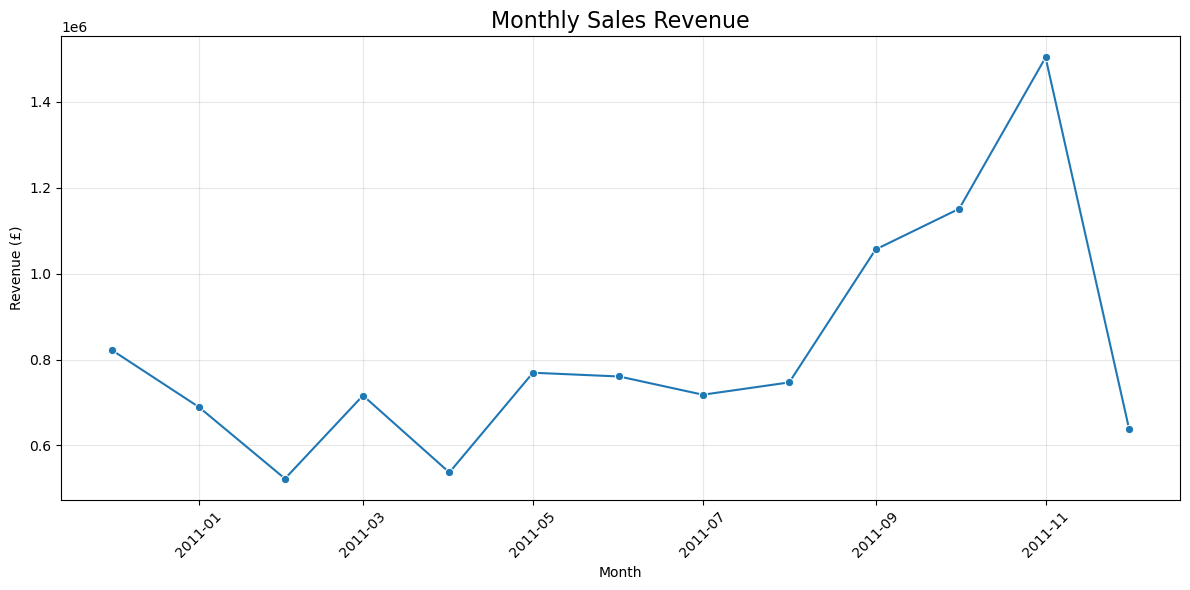

In [26]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="InvoiceDate",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Sales Revenue", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [27]:
highest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

print("Highest revenue month:",
      highest_month["InvoiceDate"].strftime("%B %Y"))
print("Revenue: £{:,.2f}".format(highest_month["Revenue"]))

print("\nLowest revenue month:",
      lowest_month["InvoiceDate"].strftime("%B %Y"))
print("Revenue: £{:,.2f}".format(lowest_month["Revenue"]))

Highest revenue month: November 2011
Revenue: £1,503,866.78

Lowest revenue month: February 2011
Revenue: £522,545.56


In [28]:
monthly_sales["MoM_Growth_%"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

monthly_sales.round(2)

,InvoiceDate,Revenue,Units_Sold,Invoices,MoM_Growth_%
0,2010-12-01,821452.73,358019,1559,NaN
1,2011-01-01,689811.61,387099,1086,-16.03
2,2011-02-01,522545.56,282934,1100,-24.25
3,2011-03-01,716215.26,376599,1454,37.06
4,2011-04-01,536968.49,307953,1246,-25.03
5,2011-05-01,769296.61,395001,1681,43.27
6,2011-06-01,760547.01,388511,1533,-1.14
7,2011-07-01,718076.12,399693,1475,-5.58
8,2011-08-01,746779.32,421019,1360,4.00
9,2011-09-01,1056435.19,569573,1837,41.47


In [29]:
monthly_sales["Invoices"] = (
    sales_analysis_df
    .groupby(sales_analysis_df["InvoiceDate"].dt.to_period("M"))["InvoiceNo"]
    .nunique()
    .values
)

monthly_sales[["InvoiceDate", "Invoices"]]

,InvoiceDate,Invoices
0,2010-12-01,1559
1,2011-01-01,1086
2,2011-02-01,1100
3,2011-03-01,1454
4,2011-04-01,1246
5,2011-05-01,1681
6,2011-06-01,1533
7,2011-07-01,1475
8,2011-08-01,1360
9,2011-09-01,1837


# PRODUCT PERFORMANCE ANALYSIS

In [30]:
# Group sales by product
product_sales = (
    sales_analysis_df
    .groupby(["StockCode", "Description"])
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

# Sort products by revenue, from highest to lowest
top_10_products = product_sales.sort_values(
    by="Revenue",
    ascending=False
).head(10)

top_10_products

,StockCode,Description,Revenue,Units_Sold
4149,DOT,DOTCOM POSTAGE,206248.77,706
1262,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
2669,47566,PARTY BUNTING,99445.23,18283
3761,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
4152,POST,POSTAGE,78101.88,3150
4150,M,Manual,77750.27,6984
1951,23084,RABBIT NIGHT LIGHT,66870.03,30739


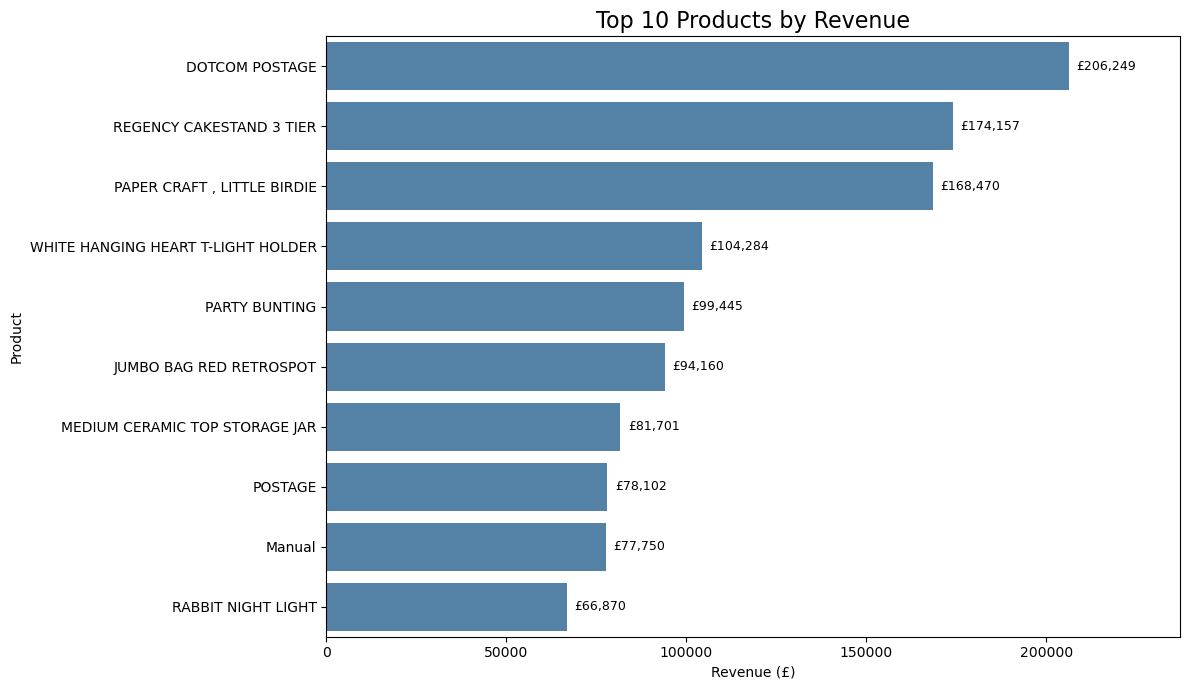

In [31]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_products,
    x="Revenue",
    y="Description",
    color="steelblue"
)

# Display the amount at the end of each bar
for bar in ax.patches:
    revenue = bar.get_width()

    ax.text(
        revenue + top_10_products["Revenue"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.xlim(0, top_10_products["Revenue"].max() * 1.15)
plt.tight_layout()
plt.show()

In [32]:
top_10_by_quantity = product_sales.sort_values(
    by="Units_Sold",
    ascending=False
).head(10)

top_10_by_quantity

,StockCode,Description,Revenue,Units_Sold
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951
3761,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
1051,22197,POPCORN HOLDER,34288.67,36749
370,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
1951,23084,RABBIT NIGHT LIGHT,66870.03,30739
1327,22492,MINI PAINT SET VINTAGE,16937.82,26633


In [33]:
# Compare products ranked by revenue and quantity
product_comparison = top_10_products[
    ["StockCode", "Description", "Revenue", "Units_Sold"]
].merge(
    top_10_by_quantity[["StockCode"]].assign(
        Top_10_by_Quantity="Yes"
    ),
    on="StockCode",
    how="left"
)

product_comparison["Top_10_by_Quantity"] = (
    product_comparison["Top_10_by_Quantity"].fillna("No")
)

product_comparison 

,StockCode,Description,Revenue,Units_Sold,Top_10_by_Quantity
0,DOT,DOTCOM POSTAGE,206248.77,706,No
1,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,No
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,Yes
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,Yes
4,47566,PARTY BUNTING,99445.23,18283,No
5,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,Yes
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,Yes
7,POST,POSTAGE,78101.88,3150,No
8,M,Manual,77750.27,6984,No
9,23084,RABBIT NIGHT LIGHT,66870.03,30739,Yes


# COUNTRY PERFORMANCE ANALYSIS

In [34]:
country_sales = (
    sales_analysis_df
    .groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique")
    )
    .reset_index()
)

country_sales = country_sales.sort_values(
    by="Revenue",
    ascending=False
)

country_sales.head(10)

,Country,Revenue,Units_Sold,Invoices,Customers
36,United Kingdom,8990682.034,4646905,18018,3920
24,Netherlands,285446.340,200361,94,9
10,EIRE,283140.520,147007,288,3
14,Germany,228678.400,119154,457,94
13,France,209625.370,112060,392,87
0,Australia,138453.810,83891,57,9
31,Spain,61558.560,27933,90,30
33,Switzerland,57067.600,30617,54,21
3,Belgium,41196.340,23237,98,25
32,Sweden,38367.830,36078,36,8


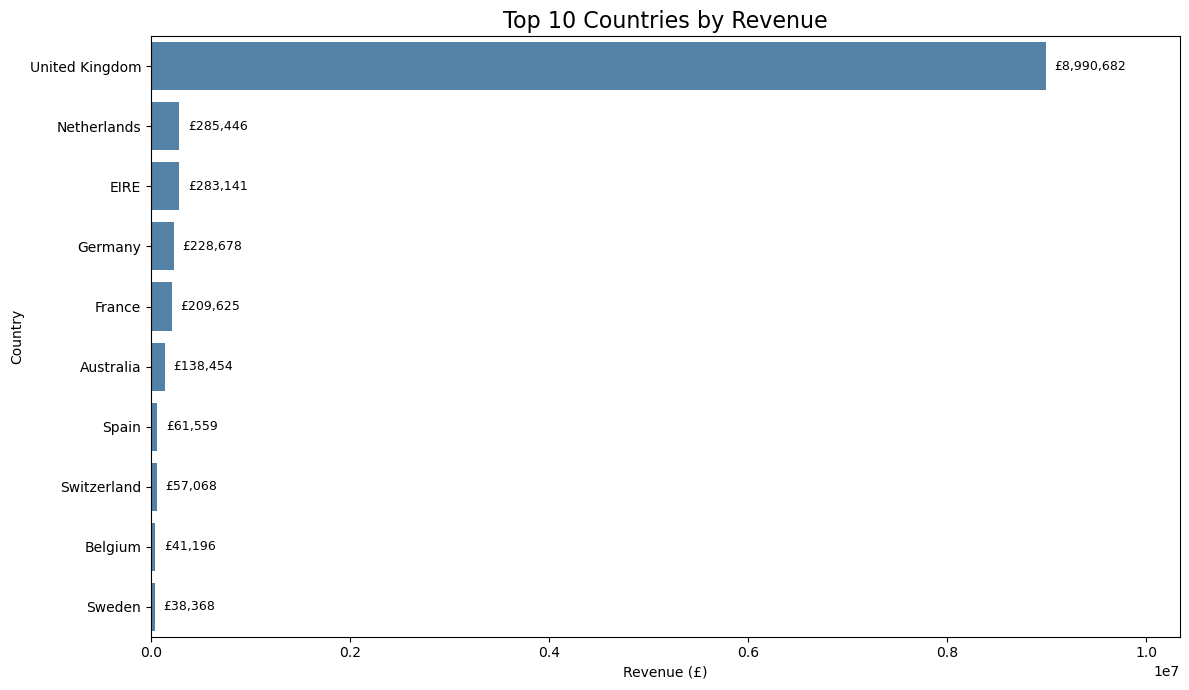

In [35]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=country_sales.head(10),
    x="Revenue",
    y="Country",
    color="steelblue"
)

# Add revenue labels at the end of each bar
for bar in ax.patches:
    revenue = bar.get_width()
    ax.text(
        revenue + country_sales["Revenue"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.xlim(0, country_sales.head(10)["Revenue"].max() * 1.15)
plt.tight_layout()
plt.show()

# CUSTOMER BEHAVIOUR ANALYSIS

In [36]:
customer_sales = (
    sales_analysis_df
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units=("Quantity", "sum"),
        Total_Invoices=("InvoiceNo", "nunique"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_sales.head()

,CustomerID,Total_Revenue,Total_Units,Total_Invoices,First_Purchase,Last_Purchase
0,12346.0,77183.60,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00
1,12347.0,4310.00,2458,7,2010-12-07 14:57:00,2011-12-07 15:52:00
2,12348.0,1797.24,2341,4,2010-12-16 19:09:00,2011-09-25 13:13:00
3,12349.0,1757.55,631,1,2011-11-21 09:51:00,2011-11-21 09:51:00
4,12350.0,334.40,197,1,2011-02-02 16:01:00,2011-02-02 16:01:00


In [37]:
top_10_customers = customer_sales.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

top_10_customers

,CustomerID,Total_Revenue,Total_Units,Total_Invoices,First_Purchase,Last_Purchase
1689,14646.0,280206.02,196915,73,2010-12-20 10:09:00,2011-12-08 12:12:00
4201,18102.0,259657.30,64124,60,2010-12-07 16:42:00,2011-12-09 11:50:00
3728,17450.0,194390.79,69973,46,2010-12-07 09:23:00,2011-12-01 13:29:00
3008,16446.0,168472.50,80997,2,2011-05-18 09:52:00,2011-12-09 09:15:00
1879,14911.0,143711.17,80240,201,2010-12-01 14:05:00,2011-12-08 15:54:00
55,12415.0,124914.53,77374,21,2011-01-06 11:12:00,2011-11-15 14:22:00
1333,14156.0,117210.08,57768,55,2010-12-03 11:48:00,2011-11-30 10:54:00
3771,17511.0,91062.38,64549,31,2010-12-01 10:19:00,2011-12-07 10:12:00
2702,16029.0,80850.84,40108,63,2010-12-01 09:57:00,2011-11-01 10:27:00
0,12346.0,77183.60,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00


In [38]:
print("Customer summary shape:", customer_sales.shape)
print("Top 10 customers shape:", top_10_customers.shape)

top_10_customers

Customer summary shape: (4338, 6)
Top 10 customers shape: (10, 6)


,CustomerID,Total_Revenue,Total_Units,Total_Invoices,First_Purchase,Last_Purchase
1689,14646.0,280206.02,196915,73,2010-12-20 10:09:00,2011-12-08 12:12:00
4201,18102.0,259657.30,64124,60,2010-12-07 16:42:00,2011-12-09 11:50:00
3728,17450.0,194390.79,69973,46,2010-12-07 09:23:00,2011-12-01 13:29:00
3008,16446.0,168472.50,80997,2,2011-05-18 09:52:00,2011-12-09 09:15:00
1879,14911.0,143711.17,80240,201,2010-12-01 14:05:00,2011-12-08 15:54:00
55,12415.0,124914.53,77374,21,2011-01-06 11:12:00,2011-11-15 14:22:00
1333,14156.0,117210.08,57768,55,2010-12-03 11:48:00,2011-11-30 10:54:00
3771,17511.0,91062.38,64549,31,2010-12-01 10:19:00,2011-12-07 10:12:00
2702,16029.0,80850.84,40108,63,2010-12-01 09:57:00,2011-11-01 10:27:00
0,12346.0,77183.60,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00


In [39]:
top_10_customers[
    ["CustomerID", "Total_Revenue"]
].describe()

,CustomerID,Total_Revenue
count,10.0000,10.000000
mean,15401.2000,153765.921000
std,2055.9313,71840.696839
min,12346.0000,77183.600000
25%,14278.5000,97599.305000
50%,15470.0000,134312.850000
75%,17199.0000,187911.217500
max,18102.0000,280206.020000


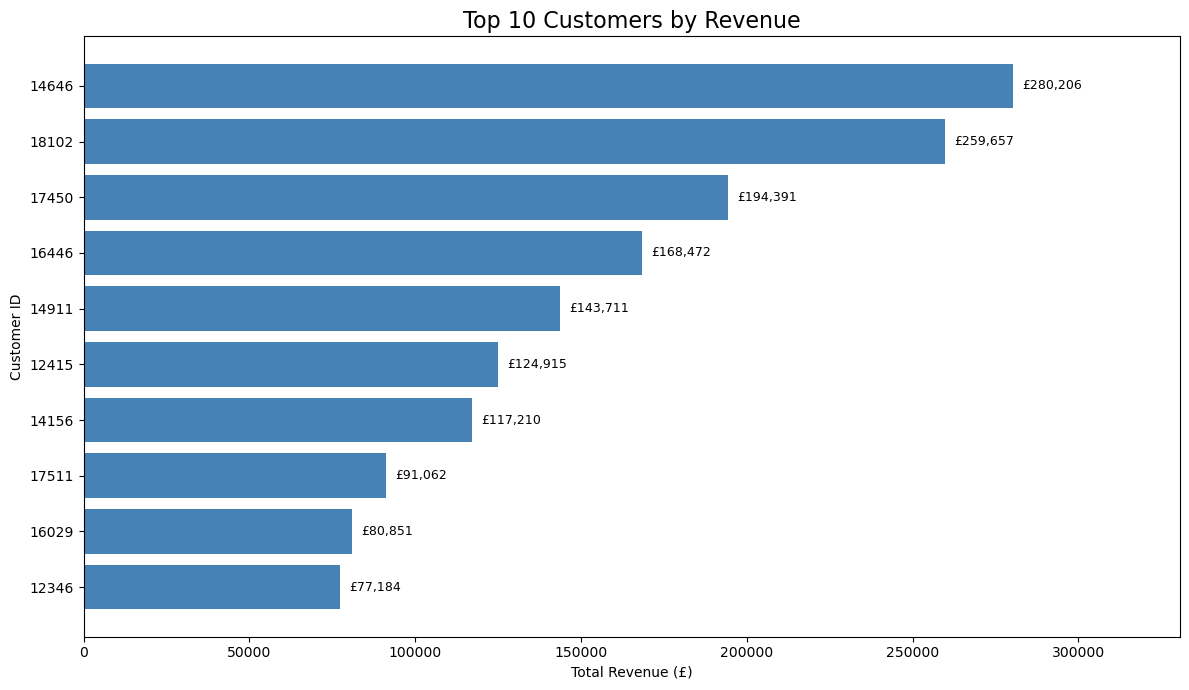

In [40]:
plt.figure(figsize=(12, 7))

customer_ids = top_10_customers["CustomerID"].astype(int).astype(str)
revenues = top_10_customers["Total_Revenue"]

plt.barh(customer_ids, revenues, color="steelblue")

for i, revenue in enumerate(revenues):
    plt.text(
        revenue + revenues.max() * 0.01,
        i,
        f"£{revenue:,.0f}",
        va="center",
        fontsize=9
    )

plt.title("Top 10 Customers by Revenue", fontsize=16)
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.xlim(0, revenues.max() * 1.18)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
# Create a repeat-purchase category
customer_sales["Purchase_Type"] = np.where(
    customer_sales["Total_Invoices"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

# Count customers in each category
purchase_summary = (
    customer_sales
    .groupby("Purchase_Type")
    .agg(
        Customer_Count=("CustomerID", "nunique"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue_Per_Customer=("Total_Revenue", "mean")
    )
    .reset_index()
)

purchase_summary

,Purchase_Type,Customer_Count,Total_Revenue,Average_Revenue_Per_Customer
0,One-time Customer,1493,613989.561,411.245520
1,Repeat Customer,2845,8273219.333,2907.985706


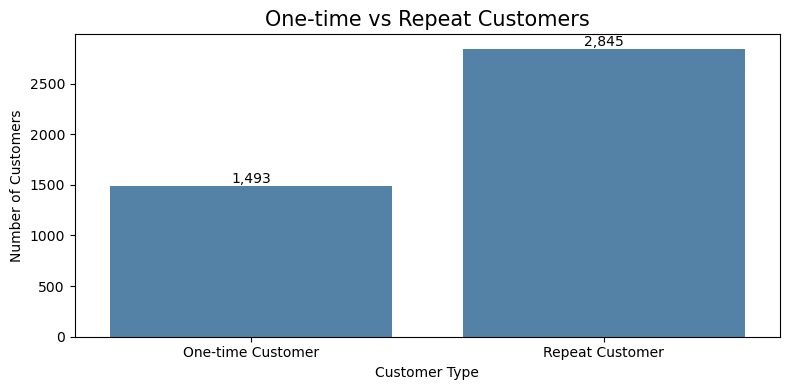

In [42]:
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=purchase_summary,
    x="Purchase_Type",
    y="Customer_Count",
    color="steelblue"
)

for bar in ax.patches:
    count = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{count:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("One-time vs Repeat Customers", fontsize=15)
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Sales Trends and Business Insights

In [43]:
monthly_aov = (
    sales_analysis_df
    .groupby(sales_analysis_df["InvoiceDate"].dt.to_period("M"))
    .agg(
        Revenue=("Revenue", "sum"),
        Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
)

monthly_aov["Average_Order_Value"] = (
    monthly_aov["Revenue"] / monthly_aov["Invoices"]
)

monthly_aov["InvoiceDate"] = (
    monthly_aov["InvoiceDate"].dt.to_timestamp()
)

monthly_aov.round(2)

,InvoiceDate,Revenue,Invoices,Average_Order_Value
0,2010-12-01,821452.73,1559,526.91
1,2011-01-01,689811.61,1086,635.19
2,2011-02-01,522545.56,1100,475.04
3,2011-03-01,716215.26,1454,492.58
4,2011-04-01,536968.49,1246,430.95
5,2011-05-01,769296.61,1681,457.64
6,2011-06-01,760547.01,1533,496.12
7,2011-07-01,718076.12,1475,486.83
8,2011-08-01,746779.32,1360,549.10
9,2011-09-01,1056435.19,1837,575.09


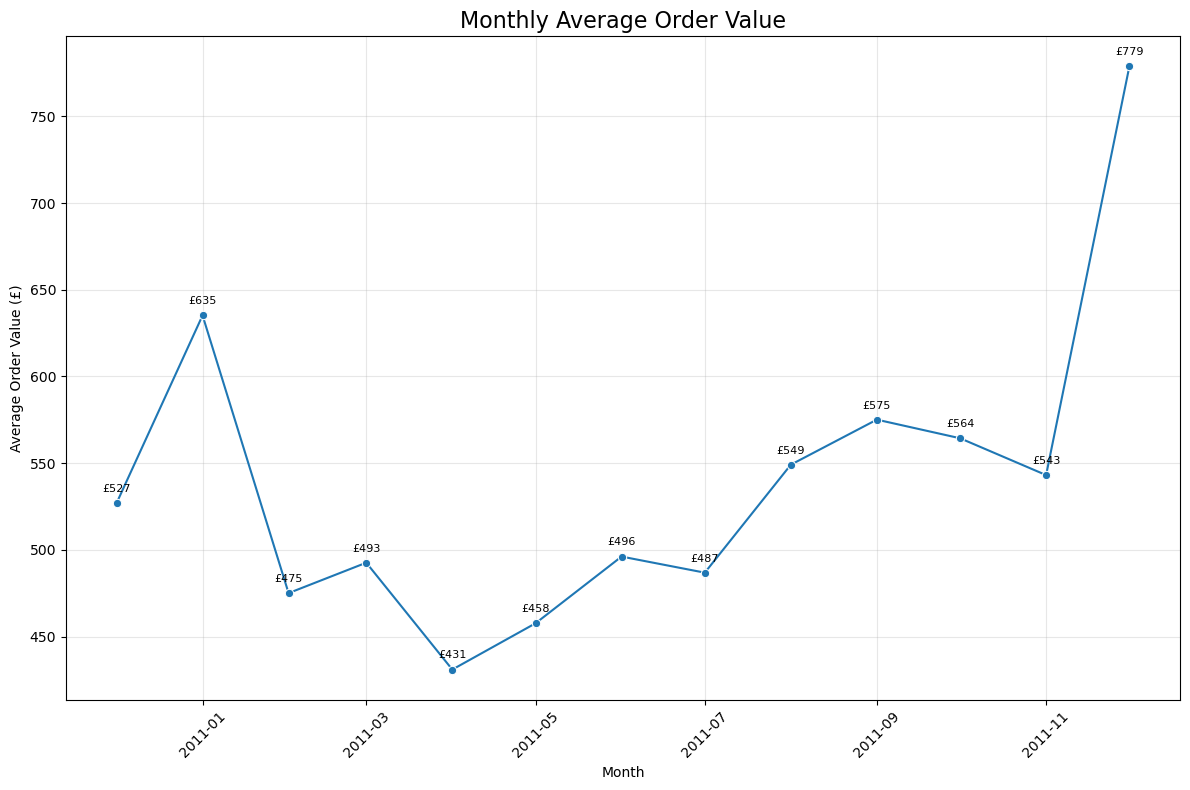

In [44]:
plt.figure(figsize=(12, 8))

ax = sns.lineplot(
    data=monthly_aov,
    x="InvoiceDate",
    y="Average_Order_Value",
    marker="o"
)

# Display the average order value beside each point
for _, row in monthly_aov.iterrows():
    ax.annotate(
        f"£{row['Average_Order_Value']:,.0f}",
        (row["InvoiceDate"], row["Average_Order_Value"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

plt.title("Monthly Average Order Value", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Order Value (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Units Sold",
        "Total Invoices",
        "Identified Customers",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_units,
        total_invoices,
        identified_customers,
        average_order_value
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,1.063105e+07
1,Total Units Sold,5.572419e+06
2,Total Invoices,1.995900e+04
3,Identified Customers,4.338000e+03
4,Average Order Value,5.326444e+02


In [46]:

# Calculate the revenue from customers with known IDs
identified_customer_revenue = customer_sales["Total_Revenue"].sum()

# Get the revenue generated by repeat customers
repeat_customer_revenue = purchase_summary.loc[
    purchase_summary["Purchase_Type"] == "Repeat Customer",
    "Total_Revenue"
].iloc[0]

# Calculate the percentage of identified-customer revenue
# generated by repeat customers
repeat_revenue_percentage = (
    repeat_customer_revenue / identified_customer_revenue
) * 100

# Display the results
print(f"Identified-customer revenue: £{identified_customer_revenue:,.2f}")
print(f"Repeat-customer revenue: £{repeat_customer_revenue:,.2f}")
print(f"Repeat-customer revenue share: {repeat_revenue_percentage:.1f}%")


Identified-customer revenue: £8,887,208.89
Repeat-customer revenue: £8,273,219.33
Repeat-customer revenue share: 93.1%


## Data Cleaning Decisions and Limitations

### Data Cleaning Decisions
- Removed exact duplicate records to reduce duplicate counting.
- Excluded cancellation invoices from the main sales analysis.
- Excluded bad-debt adjustment records because they represent accounting adjustments rather than ordinary product sales.
- Used only positive quantities and positive unit prices for the main sales performance analysis.
- Retained transactions with missing CustomerID values in overall sales calculations where they met the sales criteria.
- Calculated revenue as Quantity × UnitPrice.

### Project Limitations
- Historical data: The dataset covers December 2010 to December 2011 and may not represent current buying behaviour.
- Partial December: December 2011 data ends on December 9, making that month's total incomplete.
- Missing customer IDs: Some transactions cannot be linked to individual customers, limiting customer behaviour analysis.
- No cost information: Revenue can be calculated, but profit margins and profitability cannot be determined from this dataset alone.
- Descriptive analysis: The project identifies patterns and associations but does not establish the causes of changes in sales.

### Conclusion
This project demonstrates how Python can be used to clean retail transaction data, calculate sales KPIs, analyse monthly trends, evaluate product and country performance, and understand customer purchasing behaviour. The findings highlight the importance of repeat customers while also identifying data-quality and reporting limitations that should be considered when making business decisions.